# ETS tier-1 — quan sát backtest 4 chuỗi XK

Notebook đọc kết quả batch từ [`rice_alert_prototype.ipynb`](../rice_alert_prototype.ipynb)
(`reports/alert_backtest/`) để so alerts/năm, synthetic recall và timeline z-score.

**Các bước trong notebook**
1. Load summary JSON 4 chuỗi
2. So sánh alerts / năm
3. Synthetic recall (lượng) tại các hệ số injection
4. Vẽ timeline robust z cho một chuỗi chọn trước
5. (Tuỳ chọn) gợi ý recompute — logic đầy đủ nằm ở notebook prototype

**Tạo lại báo cáo:** mở `rice_alert_prototype.ipynb` → `RUN_BATCH = True` → Run cell batch.

Giải thích kỹ thuật: [`docs/rice_alert_prototype.md`](../docs/rice_alert_prototype.md)


In [ ]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve()
if not (ROOT / "rice_alert_prototype.ipynb").exists():
    ROOT = Path(".").resolve()

WARN, CRIT = 3.0, 4.5
BATCH_STEMS = ["gạo", "sắt thép các loại", "xăng dầu các loại", "dầu thô"]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

ALERT_DIR = ROOT / "reports" / "alert_backtest"
print("ROOT =", ROOT)
print("ALERT_DIR exists:", ALERT_DIR.exists())
print("Summaries:", sorted(p.name for p in ALERT_DIR.glob("*_summary.json")))

ROOT = C:\Homework\Code File\ML docs\Anomaly Detection
ALERT_DIR exists: True
Summaries: ['dầu thô_summary.json', 'gạo_summary.json', 'sắt thép các loại_summary.json', 'xăng dầu các loại_summary.json']


## 1. Bảng so sánh alerts / năm

Đếm WARN / CRITICAL từ summary, chia cho số năm có điểm → alerts/năm.
Mục tiêu vận hành: đủ nhạy nhưng không “nổ” quá nhiều cảnh báo.


,WARN/năm,CRITICAL/năm,WARN+CRIT/năm,n_WARN,n_CRITICAL,n_scored
series,,,,,,
dầu thô,0.54,0.46,1.00,7,6,152
gạo,0.08,0.08,0.15,1,1,152
sắt thép các loại,0.38,0.08,0.46,5,1,152
xăng dầu các loại,0.38,0.69,1.08,5,9,152


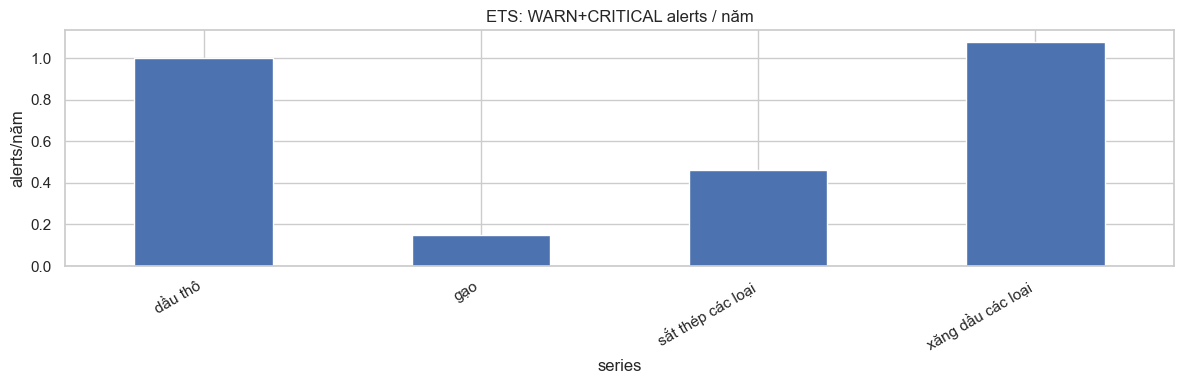

In [7]:
summaries = []
for p in sorted(ALERT_DIR.glob("*_summary.json")):
    summaries.append(json.loads(p.read_text(encoding="utf-8")))

cmp = pd.DataFrame(
    [
        {
            "series": s["series"],
            "WARN/năm": s["alerts_per_year"]["WARN"],
            "CRITICAL/năm": s["alerts_per_year"]["CRITICAL"],
            "WARN+CRIT/năm": s["alerts_per_year"]["WARN_or_CRITICAL"],
            "n_WARN": s["alert_counts"].get("WARN", 0),
            "n_CRITICAL": s["alert_counts"].get("CRITICAL", 0),
            "n_scored": s["n_months_scored"],
        }
        for s in summaries
    ]
).set_index("series")
display(cmp)

cmp["WARN+CRIT/năm"].plot(kind="bar", title="ETS: WARN+CRITICAL alerts / năm", ylabel="alerts/năm")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 2. Synthetic recall (lượng)

Recall = tỷ lệ tháng được gắn WARN trở lên khi nhân mức `so_luong` với hệ số (x2.0, x0.5, …).
Key factors cho win rule: **x2.0** và **x0.5**.


,x1.2,x1.5,x2.0,x3.0,x0.7,x0.5,x0.3
series,,,,,,,
dầu thô,0.054,0.147,0.364,0.744,0.163,0.403,0.806
gạo,0.000,0.116,0.426,0.876,0.101,0.457,0.953
sắt thép các loại,0.054,0.225,0.752,0.984,0.225,0.760,1.000
xăng dầu các loại,0.078,0.271,0.791,0.977,0.271,0.783,0.977


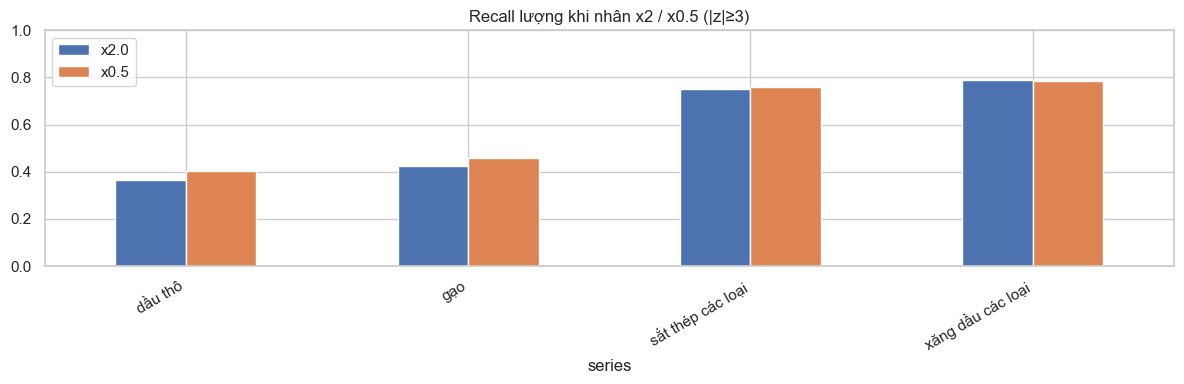

In [8]:
rows = []
for s in summaries:
    rec = s.get("synthetic_recall", {}).get("so_luong", {})
    rows.append({"series": s["series"], **rec})
rec_df = pd.DataFrame(rows).set_index("series")
display(rec_df)

ax = rec_df[["x2.0", "x0.5"]].plot(kind="bar", title="Recall lượng khi nhân x2 / x0.5 (|z|≥3)")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Timeline z-score — chọn chuỗi

Đổi `SERIES` để xem sắt thép / xăng dầu / dầu thô.
Đường ngang: WARN `|z|≥3`, CRITICAL `|z|≥4.5`.


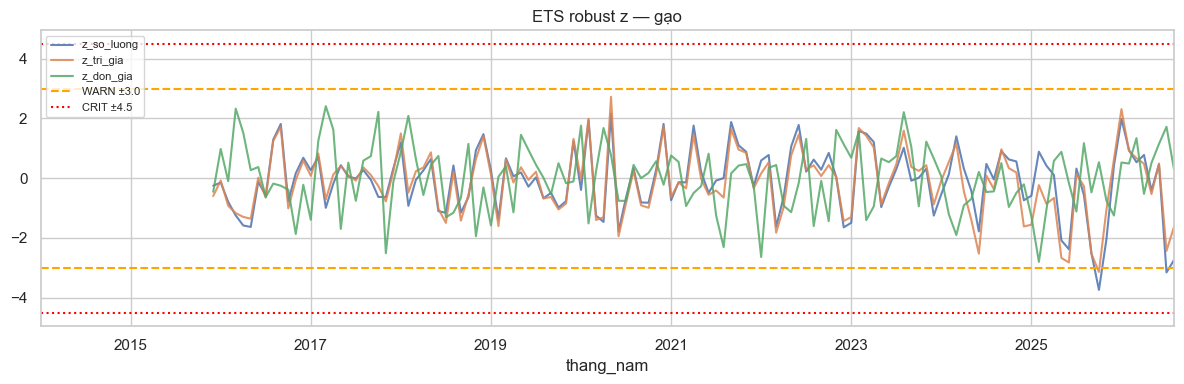

CRITICAL months:


,z_so_luong,z_tri_gia,z_don_gia,drivers
thang_nam,,,,
2025-10-01,-3.74,-3.14,0.53,"so_luong,tri_gia"


In [9]:
SERIES = "gạo"  # hoặc: sắt thép các loại | xăng dầu các loại | dầu thô
csv_path = ALERT_DIR / f"{SERIES}_alert_backtest.csv"
bt = pd.read_csv(csv_path, parse_dates=["thang_nam"]).set_index("thang_nam")

z_cols = [c for c in ["z_so_luong", "z_tri_gia", "z_don_gia"] if c in bt.columns]
ax = bt[z_cols].plot(title=f"ETS robust z — {SERIES}", alpha=0.85)
ax.axhline(WARN, color="orange", ls="--", label=f"WARN ±{WARN}")
ax.axhline(-WARN, color="orange", ls="--")
ax.axhline(CRIT, color="red", ls=":", label=f"CRIT ±{CRIT}")
ax.axhline(-CRIT, color="red", ls=":")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

print("CRITICAL months:")
display(bt[bt["alert"] == "CRITICAL"][z_cols + ["drivers"]].round(2))

## 4. (Tuỳ chọn) Chạy lại 1 chuỗi

Cell dưới chỉ là placeholder — để recompute đầy đủ hãy dùng `rice_alert_prototype.ipynb`.


In [10]:
# Placeholder — mở rice_alert_prototype.ipynb để recompute một chuỗi hoặc batch.
# path = ROOT / "data/csv/xuat_khau/gạo.csv"
print("Dùng rice_alert_prototype.ipynb để chạy lại pipeline ETS.")


Dùng rice_alert_prototype.ipynb để chạy lại pipeline ETS.


## 5. Kết quả lưu ở đâu?

- Summary JSON / CSV backtest: `reports/alert_backtest/`
- Bảng so sánh alerts/năm: cell §1 phía trên (đọc từ `*_summary.json`)
- Pipeline gốc: `rice_alert_prototype.ipynb`
